In [43]:
import os
import shutil
import re
import math
import pandas as pd
import numpy as np
import MDAnalysis as mda
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from MDAnalysis.selections.gromacs import SelectionWriter

In [32]:
%cd ..

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002


In [33]:
%cd smd
!cp ../useful/* .
!cp -pr ../input/{charmm*,index*,topol*} .
!gmx_mpi grompp -f smd.mdp -c eq.gro -p topol.top -n index.ndx -o smd.tpr
!echo -e "2\n0" | gmx_mpi trjconv -f smd.xtc -s smd.tpr -center -pbc mol -n index.ndx -o trajout.xtc
%cd ..

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/smd
                :-) GROMACS - gmx grompp, 2023-plumed_2.9.0 (-:

Executable:   /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx/bin/gmx_mpi
Data prefix:  /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx
Working dir:  /home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/smd
Command line:
  gmx_mpi grompp -f smd.mdp -c eq.gro -p topol.top -n index.ndx -o smd.tpr


NOTE 1 [file smd.mdp]:
  leapfrog does not yet support Nose-Hoover chains, nhchainlength reset to
  1

Setting the LD random seed to -22278

Generated 167799 of the 167910 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 1

Generated 117432 of the 167910 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'C

# Umbrella sampling

## Plan of today's practical

1. Prepare the umbrella simulations windows
2. Compute the potential of mean force (PMF) using WHAM
3. Compute an estimate of the error
4. Check for the convergence of the calculation

Before starting, let's create a new folder where we are going to work.


In [2]:
!mkdir practical

mkdir: cannot create directory ‘practical’: File exists


In [34]:
%cd practical

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical


## Preparing the umbrella simulations windows

The umbrella sampling procedure consists in sampling the configuration space in different regions along one (or several) collective variable(s). 
For that purpose, we generate several "windows". A window is biased simulation where we restrain the system close to a given value of the collective variable.
In each window, we apply a biasing potential (generally a harmonic potential) centered at a given value of the CV.

There are a few steps to set up the umbrella sampling procedure:

1. Select the range of values of the CV to explore:
    - Here we want we want to go from 0.3 nm to 2.0 nm.
2. Select the space between each window:
    - We generally refer to the position of a window as the position of the center of the biasing potential (if that potential is symmetric)
    - A window should allow the system to explore values of the CV present in 1-3 adjacent windows. That is necessary for the computation of the PMF later.
    - This previous constraint helps us to select an appropriate spacing between windows. However, one also has to think of the computational resources available
    - The spacing is also driven by the reaction/transformation we follow and the CV we use: the shorter the spacing, the higher the resolution of the PMF we will obtain.
    - For instance, in the case of NaCl, we could use a spacing of 0.1 nm between two windows. In each window, we generally can obtain about 2-5 points of the PMF. That means that we would be able to resolve changes of free energy linked to vibrational modes of bonded interactions. That kind of resolution is appropriate for ion-ion interactions.
3. Select the force constant that defines the stiffness of the biasing potential:
    - This part is intrinsically related to the selection of the space between two adjacent windows
    - If the free energy landscape of the system varies rapidly along the CV, then, to be able to sample correctly the change in free energy, one needs to restrain the system in a smaller portion of the configurational space, i.e. applying a potential with a stiffer force constant
    - The stiffer the force constant, the lower the distance between two adjacent windows
    - Here, we will apply a force constant of 1000 kJ/mol/nm$^{-2}$ that proved to efficiently restrain the distance, while still allowing fluctuations (as seen during the steered MD simulation).
4. Once we have an appropriate grid, we need to generate the initial configuration for each window. The initial configurations should have the system close the value of the center of the biasing potential, so that the force applied to the system won't be too intense (which would make the system to crash).

In [4]:
!mkdir dump_frames

In [35]:
%cd dump_frames

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical/dump_frames


Let's use the steered MD simulation we ran past week to generate the initial configurations for each windows:

In [36]:
xvg_file_path = '../../smd/smd_pullx.xvg'
xtc_file_path = '../../smd/trajout.xtc'
tpr_file_path = '../../smd/eq.gro'
n_windows = 18
step = -0.1
first_window = 2.0

# Read the xvg file using Pandas, skipping the header lines
with open(xvg_file_path, 'r') as xvg_file:
    header_lines = 0
    for line in xvg_file:
        if line.startswith('@') or line.startswith('#'):
            header_lines += 1
        else:
            break

xvg_data = pd.read_csv(xvg_file_path, delim_whitespace=True, skiprows=header_lines, names=['Time (ps)', 'Bias Center (nm)'])

# Load MD trajectory using MDAnalysis
universe = mda.Universe(tpr_file_path, xtc_file_path)

# Create an array of window target values
window_targets = np.arange(first_window, first_window + n_windows * step, step)

# Create a log file for recording frame information
log_file_name = 'windows.log'
with open(log_file_name, 'w') as log_file:
    log_file.write("Frame Index | Time (ps) | Bias Center (nm) | Target Value (nm)\n")

    # Store xtc timestamps and corresponding frames
    xtc_timestamps = []
    xtc_frames = []
    for ts in universe.trajectory:
        xtc_timestamps.append(ts.time)
        xtc_frames.append(ts.frame)

    for window_index, target_value in enumerate(window_targets):
        # Find the closest frame in the xvg data to the target value
        closest_frame_index = np.argmin(np.abs(xvg_data['Bias Center (nm)'] - target_value))
        closest_frame_time = xvg_data.iloc[closest_frame_index]['Time (ps)']
        closest_frame_time = float(closest_frame_time)
        
        # Find the corresponding frame in the MD trajectory
        closest_md_frame = None
        closest_time_difference = float('inf')

        # Iterate through xtc timestamps to find the corresponding frame
        for i, xtc_time in enumerate(xtc_timestamps):
            time_difference = abs(xtc_time - closest_frame_time)
            if time_difference < closest_time_difference:
                closest_md_frame = xtc_frames[i]
                closest_time_difference = time_difference

        # Debugging output
        print(f"Window {window_index + 1}/{n_windows}:")
        print(f"  Target Value: {target_value:.2f} nm")
        print(f"  Closest Frame (xvg index): {closest_frame_index}")
        print(f"  Closest Frame (MD index): {closest_md_frame}")
        print(f"  Closest Frame Time: {closest_frame_time:.2f} ps")

        # Log the information for this window
        log_line = f"{closest_md_frame:10} | {closest_frame_time:.2f} ps | {xvg_data.iloc[closest_frame_index]['Bias Center (nm)']:.2f} nm | {target_value:.2f} nm\n"
        log_file.write(log_line)

        # Save the frame as a GRO file
        gro_file_name = f'win-{window_index+1:02}.gro'
        universe.trajectory[closest_md_frame]
        universe.atoms.write(gro_file_name)

        # Print progress
        print

Window 1/18:
  Target Value: 2.00 nm
  Closest Frame (xvg index): 8
  Closest Frame (MD index): 8
  Closest Frame Time: 80.00 ps
Window 2/18:
  Target Value: 1.90 nm
  Closest Frame (xvg index): 0
  Closest Frame (MD index): 0
  Closest Frame Time: 0.00 ps
Window 3/18:
  Target Value: 1.80 nm
  Closest Frame (xvg index): 22
  Closest Frame (MD index): 22
  Closest Frame Time: 220.00 ps
Window 4/18:
  Target Value: 1.70 nm
  Closest Frame (xvg index): 36
  Closest Frame (MD index): 36
  Closest Frame Time: 360.00 ps
Window 5/18:
  Target Value: 1.60 nm
  Closest Frame (xvg index): 56
  Closest Frame (MD index): 56
  Closest Frame Time: 560.00 ps
Window 6/18:
  Target Value: 1.50 nm
  Closest Frame (xvg index): 65
  Closest Frame (MD index): 65
  Closest Frame Time: 650.00 ps
Window 7/18:
  Target Value: 1.40 nm
  Closest Frame (xvg index): 71
  Closest Frame (MD index): 71
  Closest Frame Time: 710.00 ps
Window 8/18:
  Target Value: 1.30 nm
  Closest Frame (xvg index): 86
  Closest Fram

Once we obtain the initial configuration, it is customary to create one directory for each window, in which each of the umbrella sampling runs are going to be computed.

In [38]:
# Define parameters
n_windows = 18
step = -0.1
first_window = 2.0
input_path = "../../input"

# Loop over the windows to create directories and copy files
for win_id in range(1, n_windows + 1):
    # Calculate the CV value for this window
    cv_value = first_window + (win_id - 1) * step
    win_dir = f"{win_id:02d}"

    # Create the directory if it doesn't exist
    os.makedirs(win_dir, exist_ok=True)

    # Copy all files and directories from input_path to the window directory
    for item in os.listdir(input_path):
        src = os.path.join(input_path, item)
        dst = os.path.join(win_dir, item)
        
        if os.path.isdir(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
        else:
            shutil.copy2(src, dst)

    # Set the CV value (replacing <INIT> pattern) in md.mdp to the current CV value
    md_mdp_path = os.path.join(win_dir, "md.mdp")
    with open(md_mdp_path, "r") as file:
        md_mdp_content = file.read()
    
    # Replace <INIT> with the current CV value
    md_mdp_content = re.sub(r"<INIT>", f"{cv_value:.2f}", md_mdp_content)
    
    # Write the modified content back to md.mdp
    with open(md_mdp_path, "w") as file:
        file.write(md_mdp_content)

    # Copy and rename win-{win_id}.gro to init.gro in the window directory
    gro_file_src = f"win-{win_dir}.gro"
    gro_file_dst = os.path.join(win_dir, "init.gro")
    
    if os.path.exists(gro_file_src):
        shutil.copy2(gro_file_src, gro_file_dst)
    else:
        print(f"Warning: {gro_file_src} does not exist and will be skipped.")

print("All windows have been set up.")

All windows have been set up.


## Analyzing the results

### Checking the Umbrella Sampling parameters

Before going any further, let's try to understand whether the spacing between windows and the force constant we use are an adequate set of parameters.

For that we want to look at the output from GROMACS pull code:

In [39]:
%cd ..
!mkdir us_parameters
%cd us_parameters

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical
/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical/us_parameters


/tmp/ipykernel_95911/2233433278.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', num_windows)


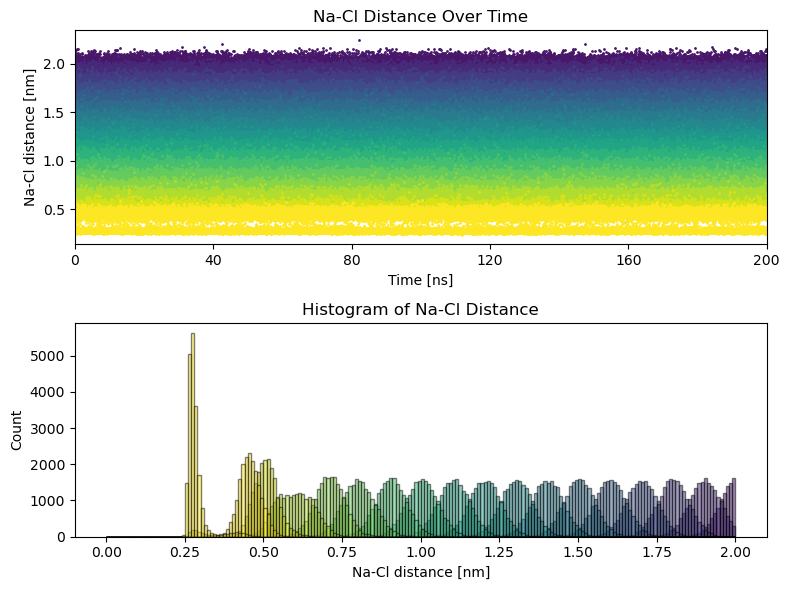

In [46]:
# Define number of windows to plot
num_windows = 18  # Update this to the desired number of windows

# Labels
x_label_top = 'Time [ns]'
y_label_top = 'Na-Cl distance [nm]'
x_label_bottom = 'Na-Cl distance [nm]'
y_label_bottom = 'Count'

# Create a single figure with two subplots for all windows
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=False)

# Set up a color map for gradient colors across windows
cmap = cm.get_cmap('viridis', num_windows)

# Iterate over each window and add its data to the plot
for win_id in range(1, num_windows + 1):
    # Load the xvg file for the current window
    xvg_file = f"../../us/us_{win_id:02d}_px.xvg"
    data = np.loadtxt(xvg_file, comments=['@', '#'])
    
    # Separate the x and y data
    time = data[:, 0] / 1000  # Convert ps to ns
    na_cl_distance = data[:, 1]
    
    # Choose a color from the colormap for each window
    color = cmap(win_id / num_windows)
    
    # Scatter plot for Na-Cl distance over time in the first subplot
    ax1.scatter(time, na_cl_distance, color=color, s=1)  # Gradient color
    ax1.set_xlim(0, 200)  # Time range from 0 to 200 ns
    ax1.set_xticks(np.arange(0, 201, 40))  # Major step of 40 ns
    ax1.set_xlabel(x_label_top)
    ax1.set_ylabel(y_label_top)
    ax1.set_title('Na-Cl Distance Over Time')
    
    # Histogram for Na-Cl distance in the second subplot
    bins = np.arange(0, 2.01, 0.01)  # Bins from 0 to 2.0 with 0.01 spacing
    ax2.hist(na_cl_distance, bins=bins, color=color, alpha=0.5, edgecolor='black')

# Set labels and title for histogram plot
ax2.set_xlabel(x_label_bottom)
ax2.set_ylabel(y_label_bottom)
ax2.set_title('Histogram of Na-Cl Distance')

# Adjust the layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

## Using gmx wham

GROMACS WHAM (Weight Histogram Analysis Method) is the software included in GROMACS package and the method used to compute the free energy profile. It aims at removing the biasing potential from all the data.

### Let's start to look at the many options of <code>gmx wham</code>

1. <code>-bins</code> the number of bins, _i.e._ the number of points of free energy that will be estimated. A good starting guess is around 5 bin / window. You can plot the histogram of a window with different numbers to see that the minimal count is not too low.
2. <code>-temp</code> the temperature
3. <code>-tol</code> the tolerance used to assume that WHAM converged to a set of values of the free energy. A precision of 1e-5 is enough for a quick look at the profile. 1e-6 is the default and most common value. In some case, it makes sense to go up to 1e-8.
4. <code>-auto</code>, <code>-min</code>, <code>-max</code> the way to estimate the boundaries for which free energy values are computed. I would recommend to use the center of the first and last window by default.
5. <code>-b</code>, <code>-e</code> the beginning and ending time to be used. That is very important to produce a computation only on a converged part of the data and to check the convergence.
6. <code>-cycl</code> WHAM is applied with cyclic PBC, meaning that it assumes continuity between to 1st and last window. That is useful for system which have supposedly the same initial and final state (for instance, a molecule in the bulk water).
7. <code>-ix</code>, <code>-if</code> the input files to refer to the output files from Gromacs where the CV output or the forces output are stored (xvg files). These files should only have the path to the data files produced during the US procedure.
8. <code>-it</code> the path to the tpr. From the tpr, the pulling code is read by <code>gmx wham</code> to know the number of CVs and the values of the force constant for each window.
9. <code>-is</code> refers to a file mentioning which CVs should be used to compute the free energy.
10. <code>-o</code>, <code>-hist</code> the names of the output files.
11. <code>-bs-method</code>, <code>-nBootstrap</code>, the bootstrapping method is the one we will use to estimate the statistical error. We will use the default Bayesian implementation "b-hist". Generally, 100-200 bootstraps are enough. Bootstrapping method allows to estimate the statistical errors by making multiple (nbootstrap) guesses of the probability distribution. To obtain several guesses, random weights on the individual probability distributions of the different windows are applied. Mind that to not underestimate the error, one should have a very good overlap of multiple windows, **which is generally not the case**.


### 1.2. Tasks

Let's use the command help, together, to compute a simple free energy profile.
- Compute the free energy for the whole profile, for all the simulation long. Any comment?


In [50]:
!gmx_mpi wham -h

                 :-) GROMACS - gmx wham, 2023-plumed_2.9.0 (-:

Executable:   /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx/bin/gmx_mpi
Data prefix:  /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx
Working dir:  /home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical/us_parameters
Command line:
  gmx_mpi wham -h

SYNOPSIS

gmx wham [-ix [<.dat>]] [-if [<.dat>]] [-it [<.dat>]] [-is [<.dat>]]
         [-iiact [<.dat>]] [-tab [<.dat>]] [-o [<.xvg>]] [-hist [<.xvg>]]
         [-oiact [<.xvg>]] [-bsres [<.xvg>]] [-bsprof [<.xvg>]] [-xvg <enum>]
         [-min <real>] [-max <real>] [-[no]auto] [-bins <int>] [-temp <real>]
         [-tol <real>] [-[no]v] [-b <real>] [-e <real>] [-dt <real>]
         [-[no]histonly] [-[no]boundsonly] [-[no]log] [-unit <enum>]
         [-zprof0 <real>] [-[no]cycl] [-[no]sym] [-[no]ac] [-acsig <real>]
         [-ac-trestart

In [60]:
%cd ..
!mkdir wham
%cd wham
!ln -s ../../us/* .

/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical
/home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical/wham


Let's create the necessary input files that point at our data:

In [61]:
# Define the range of window indices
window_range = range(1, 19)  # Windows 01 to 18

# Open the files for writing
with open('tprFile.dat', 'w') as tpr_file, open('pullxFile.dat', 'w') as pullx_file:
    for win in window_range:
        # Format the window index with leading zeros
        win_str = f"{win:02d}"
        
        # Write the corresponding filenames to each file
        tpr_file.write(f"us_{win_str}.tpr\n")
        pullx_file.write(f"us_{win_str}_px.xvg\n")

In [62]:
! cat *dat

us_01_px.xvg
us_02_px.xvg
us_03_px.xvg
us_04_px.xvg
us_05_px.xvg
us_06_px.xvg
us_07_px.xvg
us_08_px.xvg
us_09_px.xvg
us_10_px.xvg
us_11_px.xvg
us_12_px.xvg
us_13_px.xvg
us_14_px.xvg
us_15_px.xvg
us_16_px.xvg
us_17_px.xvg
us_18_px.xvg
us_01.tpr
us_02.tpr
us_03.tpr
us_04.tpr
us_05.tpr
us_06.tpr
us_07.tpr
us_08.tpr
us_09.tpr
us_10.tpr
us_11.tpr
us_12.tpr
us_13.tpr
us_14.tpr
us_15.tpr
us_16.tpr
us_17.tpr
us_18.tpr


In [63]:
!gmx_mpi wham -it tprFile.dat -ix pullxFile.dat -hist hist_full.xvg -o profile_full.xvg -tol 1e-7 -unit kJ -min 0.4 -max 2.0 

                 :-) GROMACS - gmx wham, 2023-plumed_2.9.0 (-:

Executable:   /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx/bin/gmx_mpi
Data prefix:  /home/tim/spack/opt/spack/linux-ubuntu22.04-skylake/gcc-12.3.0/gromacs-2023-2wg3ad7k77e3v5ag4c3pmv3rqcjeacxx
Working dir:  /home/tim/work/admin/22.md-lesson/10.fall_24/clone/week07_v002/practical/wham
Command line:
  gmx_mpi wham -it tprFile.dat -ix pullxFile.dat -hist hist_full.xvg -o profile_full.xvg -tol 1e-7 -unit kJ -min 0.4 -max 2.0

Note: min and max given, switching off -auto.
Found 18 tpr and 18 pull position files in tprFile.dat and pullxFile.dat, respectively
Reading 18 tpr and pullx/pullf files
Reading file us_01.tpr, VERSION 2022.3-plumed_2.8.1 (single precision)
Note: file tpx version 127, software tpx version 129

File us_01.tpr, 1 coordinates, with these options:
	Geometry distance   k = 1000      position = 2         dimensions [Y Y Y] (3 dimensions). Used: Ye

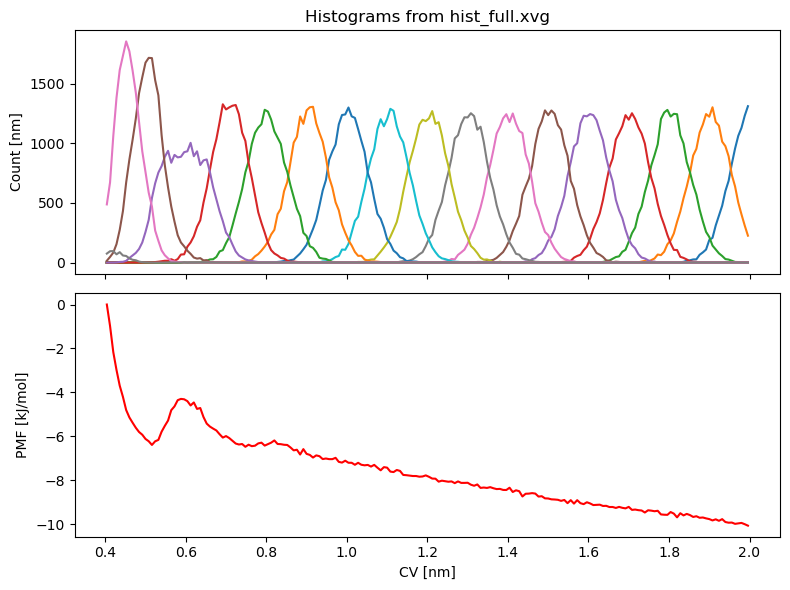

In [67]:
# Load the xvg files from the SMD simulation
xvg_file_x = 'hist_full.xvg'
data_x = np.loadtxt(xvg_file_x, comments=['@', '#'])

# Load the xvg files for the profile
xvg_file_f = 'profile_full.xvg'
data_f = np.loadtxt(xvg_file_f, comments=['@', '#'])

# Separate the x and y data
x_x = data_x[:, 0]  # Assuming the first column is the x-axis (CV)
y_x = data_x[:, 1:]  # All remaining columns are y-values for multiple curves

x_f = data_f[:, 0]  # Assuming the first column is the x-axis (e.g., distance)
y_f = data_f[:, 1]  # Assuming the second column is the PMF data

# Labels
x_label_x = 'CV [nm]'
y_label_x = 'Count [nm]'
y_label_f = 'PMF [kJ/mol]'

# Create a Matplotlib figure with two subplots (one for each dataset)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Plot the first dataset in the first subplot (multiple curves from hist_full.xvg)
for i in range(y_x.shape[1]):  # Loop through each column of data_x (except the first column)
    ax1.plot(x_x, y_x[:, i], label=f'Curve {i+1}')  # Plot each curve with a label

ax1.set_ylabel(y_label_x)
ax1.set_title('Histograms from hist_full.xvg')

# Plot the second dataset in the second subplot
ax2.plot(x_f, y_f, label='PMF', linestyle='-', color='r')
ax2.set_xlabel(x_label_x)
ax2.set_ylabel(y_label_f)

# Adjust the layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

Now that you did that once, try by yourself to 
- Compute the free energy multiple times, by chunks of 20 ns.
- Try to estimate the errors